# 📈 Time Series Analysis & Forecasting
## 🛠️ Datetime Basics (Step-by-Step)

**Summary:** Is notebook mein hum seekh rahe hain ki Python mein tareeq (Date) aur waqt (Time) ke sath kaise khela jata hai. Yeh Time Series Analysis ka pehla aur sabse zaroori step hai.

In [1]:
# Sabse pehle Python ki datetime library ko import karenge
from datetime import datetime

In [2]:
# Computer ka maujuda date aur time 'now' naam ke variable mein save kar rahe hain
now = datetime.now()

# Isko check karne ke liye run karein
now

datetime.datetime(2026, 7, 7, 17, 8, 8, 916107)

In [3]:
# 'now' mein se sirf saal (Year) nikaalna
now.year

2026

In [4]:
# 'now' mein se sirf mahina (Month) nikaalna (1 se 12 ke beech)
now.month

7

In [5]:
# 'now' mein se sirf aaj ki tareeq (Day) nikaalna (1 se 31 ke beech)
now.day

7

In [6]:
# 'now' mein se sirf ghanta (Hour) nikaalna (24-hour format mein)
now.hour

17

In [7]:
# Poore waqt mein se time hata kar sirf Date (YYYY-MM-DD) dekhna
now.date()

datetime.date(2026, 7, 7)

In [8]:
# Date hata kar sirf maujuda Time (HH:MM:SS) dekhna
now.time()

datetime.time(17, 8, 8, 916107)

In [9]:
# Haftay ka din nikaalna (Python mein Monday=0, Tuesday=1, Wednesday=2... hota hai)
now.weekday()

1

In [10]:
# Agar aapke paas excel ya data mein date text format ('2026-07-02') mein ho, 
# toh use machine ke samajhne ke liye proper date object mein badalna:
datetime.strptime('2026-07-02', "%Y-%m-%d")

datetime.datetime(2026, 7, 2, 0, 0)

## 🚀 Advance Time Series Operations with Pandas

**Summary:** Ab hum seekhenge ki kaise pure mahine ka data ek sath generate kiya jata hai, missing values ko kaise handle karte hain, aur data ko graph (plot) par kaise dekhte hain.

In [11]:
import pandas as pd
import numpy as np

# Maan lijiye aapko July 2026 ke pure mahine ki dates chahiye. 
# Manually likhne ki jagah Pandas ka 'date_range' use karein:
july_dates = pd.date_range(start='2026-07-01', end='2026-07-31', freq='D')

# Dekhte hain Pandas ne kaise pure mahine ki dates bana dein
july_dates

DatetimeIndex(['2026-07-01', '2026-07-02', '2026-07-03', '2026-07-04',
               '2026-07-05', '2026-07-06', '2026-07-07', '2026-07-08',
               '2026-07-09', '2026-07-10', '2026-07-11', '2026-07-12',
               '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16',
               '2026-07-17', '2026-07-18', '2026-07-19', '2026-07-20',
               '2026-07-21', '2026-07-22', '2026-07-23', '2026-07-24',
               '2026-07-25', '2026-07-26', '2026-07-27', '2026-07-28',
               '2026-07-29', '2026-07-30', '2026-07-31'],
              dtype='datetime64[ns]', freq='D')

In [13]:
# Hum farz karte hain ki yeh kisi dukaan ki July ke mahine ki daily SALES (bikri) ka data hai.
# Hum 31 dino ke liye random sales numbers generate kar rahe hain.
np.random.seed(42) # Taaki aapka aur mera output same aaye
sales_data = np.random.randint(100, 500, size=len(july_dates))

# Ab in dates aur sales ko mila kar ek DataFrame (Table) banate hain
df = pd.DataFrame({'Sales': sales_data}, index=july_dates)

# Dataset ki pehli 5 rows dekhne ke liye:
df.head()

,Sales
2026-07-01,202
2026-07-02,448
2026-07-03,370
2026-07-04,206
2026-07-05,171


In [14]:
# Pandas ka sabse bada faida! Agar mujhe sirf 10 July se 15 July tak ki sales chahiye:
df.loc['2026-07-10':'2026-07-15']

,Sales
2026-07-10,314
2026-07-11,430
2026-07-12,187
2026-07-13,472
2026-07-14,199
2026-07-15,459


In [15]:
# Agar aapka boss bole ki mujhe daily sales nahi, har HAFTE (Weekly) ki total sales chahiye:
# 'W' ka matlab hai Weekly, aur .sum() ka matlab hai total jama karna.
weekly_sales = df.resample('W').sum()

weekly_sales

,Sales
2026-07-05,1397
2026-07-12,1762
2026-07-19,2268
2026-07-26,2605
2026-08-02,1665


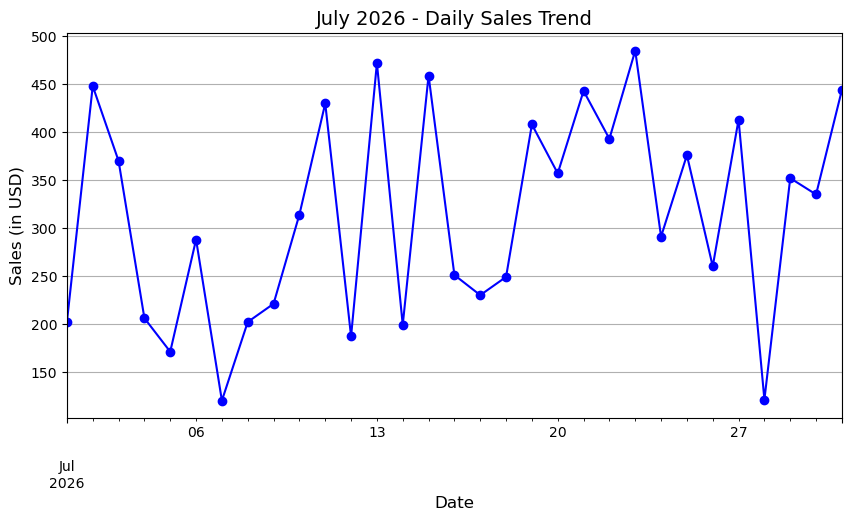

In [17]:
# Ab is sales ke data ko ek sunder se graph par dekhne ke liye line plot banate hain:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
df['Sales'].plot(color='blue', marker='o', linestyle='-')

# Graph ke upar headings lagana
plt.title('July 2026 - Daily Sales Trend', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales (in USD)', fontsize=12)
plt.grid(True) # Peeche lines (grid) dikhane ke liye

# Graph show karna
plt.show()

In [18]:
# Hum jaan booch kar 3 dates (July 5, July 12, aur July 20) ka data gayab (NaN) kar rahe hain
df.loc['2026-07-05', 'Sales'] = np.nan
df.loc['2026-07-12', 'Sales'] = np.nan
df.loc['2026-07-20', 'Sales'] = np.nan

# Check karte hain ki data mein missing values kahan kahan hain
print("Total Missing Values:\n", df.isnull().sum())

# Missing values wali rows ko dekhne ke liye:
df.loc[['2026-07-04', '2026-07-05', '2026-07-06']]# Hum jaan booch kar 3 dates (July 5, July 12, aur July 20) ka data gayab (NaN) kar rahe hain
df.loc['2026-07-05', 'Sales'] = np.nan
df.loc['2026-07-12', 'Sales'] = np.nan
df.loc['2026-07-20', 'Sales'] = np.nan

# Check karte hain ki data mein missing values kahan kahan hain
print("Total Missing Values:\n", df.isnull().sum())

# Missing values wali rows ko dekhne ke liye:
df.loc[['2026-07-04', '2026-07-05', '2026-07-06']]

Total Missing Values:
 Sales    3
dtype: int64
Total Missing Values:
 Sales    3
dtype: int64


,Sales
2026-07-04,206.0
2026-07-05,NaN
2026-07-06,288.0


In [19]:
# Data ko saaf karne ke 2 behtareen tareeqe hain:
# Tareeqa 1: ffill (Forward Fill) - Isse pichle din ki sales agle khali din mein khud ba khud aa jati hai.
# Tareeqa 2: bfill (Backward Fill) - Isse agle din ki sales pichle khali din mein aa jati hai.

# Hum 'ffill' use karke data ko saaf kar rahe hain taaki blank jagah bhar jaye
df_cleaned = df.ffill()

# Check karte hain ki kya ab bhi koi missing value bachi hai?
print("Cleaning ke baad missing values:", df_cleaned.isnull().sum())

# Dubara 5 July ka data check karte hain (yeh ab 4 July wali sales se bhar chuka hoga)
df_cleaned.loc[['2026-07-04', '2026-07-05', '2026-07-06']]

Cleaning ke baad missing values: Sales    0
dtype: int64


,Sales
2026-07-04,206.0
2026-07-05,206.0
2026-07-06,288.0


## 🔄 Step 21: Rolling Windows & Moving Average (Trend Pehchanna)

**Summary:** Sales ka data har din upar-neeche hota rehta hai (jisey noise kehte hain). Hum 7-days ka Moving Average nikaalenge taaki hume asli trend samajh aa sake ki sales overall barh rahi hain ya kam ho rahi hain.

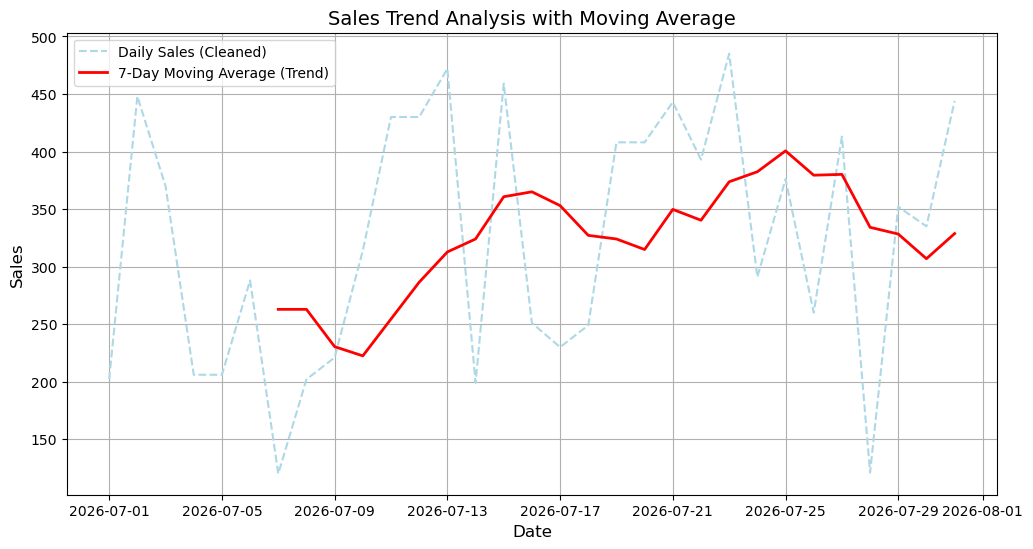

In [21]:
# Har 7 dino ka average nikaal kar ek naya column banate hain
df_cleaned['7_Day_MA'] = df_cleaned['Sales'].rolling(window=7).mean()

# Dono columns (Asli Sales aur 7-Day Average) ka graph banakar dekhte hain
plt.figure(figsize=(12, 6))
plt.plot(df_cleaned.index, df_cleaned['Sales'], label='Daily Sales (Cleaned)', color='lightblue', linestyle='--')
plt.plot(df_cleaned.index, df_cleaned['7_Day_MA'], label='7-Day Moving Average (Trend)', color='red', linewidth=2)

plt.title('Sales Trend Analysis with Moving Average', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales', fontsize=12)
plt.legend() # Graph ke kone mein labels dikhane ke liye
plt.grid(True)
plt.show()

In [1]:
from datetime import datetime
import numpy as np
import pandas as pd

In [3]:
# Computer ka maujuda date aur time 'now' variable mein save kar rahe hain
now = datetime.now()

# Output dekhne ke liye
now

datetime.datetime(2026, 7, 9, 11, 11, 41, 639656)

In [4]:
# Yahan hum khud se thoda data aur dates bana kar unhein pd.Series mein convert kar rahe hain.
# Sample dates aur data create kar rahe hain
dates = [datetime(2026, 1, 1), datetime(2026, 1, 2), datetime(2026, 1, 3)]
data = [10, 20, 30]

# Time series banana
ts = pd.Series(data, index=dates)

# Output dekhne ke liye
ts

2026-01-01    10
2026-01-02    20
2026-01-03    30
dtype: int64

In [5]:
# Yahan hum 1000 ghanton ka random data bana rahe hain. Humne freq='H' ki jagah freq='h' kiya hai taake warning na aaye.
# 1/1/2000 se agle 1000 ghanton ka random data banana
longer_ts = pd.Series(
    np.random.randn(1000),
    index=pd.date_range("1/1/2000", periods=1000, freq="h"),
)

# Output ki shuruat ki rows dekhne ke liye
longer_ts.head()

2000-01-01 00:00:00   -1.543205
2000-01-01 01:00:00   -0.365023
2000-01-01 02:00:00    1.431419
2000-01-01 03:00:00   -1.028290
2000-01-01 04:00:00   -0.627624
Freq: h, dtype: float64

In [6]:
# Is cell mein hum poore data mein se sirf January 2000 aur February 2000 ka data alag kar rahe hain.
# January se February ka data slice (alag) karna
longer_ts["2000-01":"2000-02"]

2000-01-01 00:00:00   -1.543205
2000-01-01 01:00:00   -0.365023
2000-01-01 02:00:00    1.431419
2000-01-01 03:00:00   -1.028290
2000-01-01 04:00:00   -0.627624
                         ...   
2000-02-11 11:00:00   -0.498761
2000-02-11 12:00:00    1.653925
2000-02-11 13:00:00    0.316062
2000-02-11 14:00:00   -1.171352
2000-02-11 15:00:00    0.408077
Freq: h, Length: 1000, dtype: float64

In [7]:
# Isse hum check kar rahe hain ke 1 January 2000 ke poore din mein sab se bari (maximum) value kaun si thi.
# 1 January 2000 ke data mein se sab se badi value nikalna
longer_ts["2000-01-01"].max()

2.5790231494883398

In [8]:
# Resampling ka matlab hai data ka interval badalna. Kyonke hamara asal data ghanton (Hours) ka tha, is command se Pandas har din ka alag se data jama 
# karega aur us din ki sab se bari (max()) value dikhaye ga.
# Hourly data ko Daily data mein badalna aur har din ka max nikalna
longer_ts.resample("D").max()

2000-01-01    2.579023
2000-01-02    1.918369
2000-01-03    2.407549
2000-01-04    1.988207
2000-01-05    1.346899
2000-01-06    2.112931
2000-01-07    2.300750
2000-01-08    2.011904
2000-01-09    2.586556
2000-01-10    1.757115
2000-01-11    1.843150
2000-01-12    1.383763
2000-01-13    2.027944
2000-01-14    1.838867
2000-01-15    1.322463
2000-01-16    1.875277
2000-01-17    1.122216
2000-01-18    1.139631
2000-01-19    1.612526
2000-01-20    2.088898
2000-01-21    2.137335
2000-01-22    1.819452
2000-01-23    2.290317
2000-01-24    1.418885
2000-01-25    1.788493
2000-01-26    1.841066
2000-01-27    0.953907
2000-01-28    1.171682
2000-01-29    2.021216
2000-01-30    2.111806
2000-01-31    2.408091
2000-02-01    1.895094
2000-02-02    1.518666
2000-02-03    1.986064
2000-02-04    2.307477
2000-02-05    2.135717
2000-02-06    1.706667
2000-02-07    1.949651
2000-02-08    1.544117
2000-02-09    2.418126
2000-02-10    1.648715
2000-02-11    1.894786
Freq: D, dtype: float64

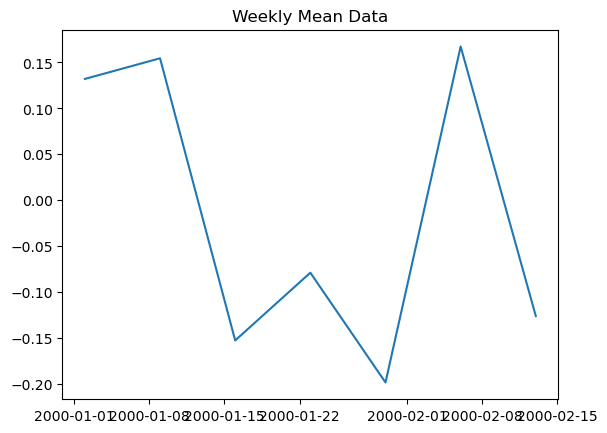

In [9]:
# Yahan hum data ko haftawar ('W' yani Weekly) badal rahe hain, uska average (mean()) nikal rahe hain, aur uska ek line graph plot kar rahe hain.
import matplotlib.pyplot as plt

# Weekly average ka line graph banana
plt.plot(longer_ts.resample("W").mean())
plt.title("Weekly Mean Data")
plt.show()

In [10]:
# Isse aapko pata chalega ke pure 1000 ghanton ke data mein sab se bari value kaun si thi.
# Poore dataset ki sab se badi value
longer_ts.max()

2.586556067290326

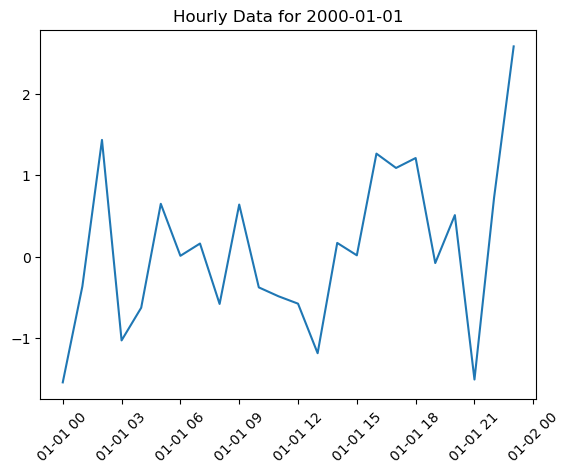

In [11]:
# Isse sirf 1 January 2000 ke 24 ghanton ka data graph par show hoga.
# 1 January ka hourly data plot karna
plt.plot(longer_ts["2000-01-01"])
plt.title("Hourly Data for 2000-01-01")
plt.xticks(rotation=45)  # Taake dates/time aapas mein mix na hon
plt.show()

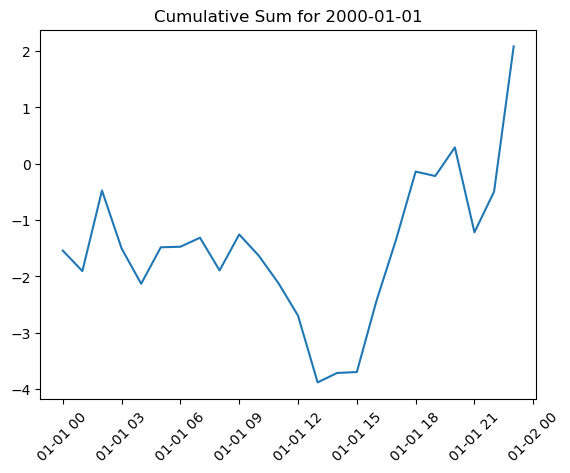

In [12]:
# cumsum() har aane wali value ko pichli value mein plus (add) karti jati hai. Isse trend pata chalta hai.
# 1 January ke data ka cumulative sum plot karna
plt.plot(longer_ts["2000-01-01"].cumsum())
plt.title("Cumulative Sum for 2000-01-01")
plt.xticks(rotation=45)
plt.show()

In [13]:
# Ab yahan se aapka data change ho raha hai. Ab hum 1000 ghanton ke bajaye 1000 dinon (Days) ka random data bana rahe hain.
# Ab data ko Daily ('D') frequency ke sath 1000 dino ke liye generate karna
longer_ts = pd.Series(
    np.random.randn(1000),
    index=pd.date_range("1/1/2000", periods=1000, freq="D"),
)

# Naye data ko dekhne ke liye
longer_ts

2000-01-01   -0.317968
2000-01-02   -0.187726
2000-01-03    0.363805
2000-01-04   -1.883109
2000-01-05    0.687885
                ...   
2002-09-22    0.747746
2002-09-23   -0.267912
2002-09-24    0.184590
2002-09-25    1.166536
2002-09-26    0.923223
Freq: D, Length: 1000, dtype: float64

In [14]:
# Daily data ko Quarterly badalna aur total sum nikalna
longer_ts.resample("Q").sum()

C:\Users\Adil\AppData\Local\Temp\ipykernel_15308\3871136078.py:2: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  longer_ts.resample("Q").sum()


2000-03-31     8.890936
2000-06-30     8.172745
2000-09-30   -15.293637
2000-12-31    -4.841081
2001-03-31     1.280541
2001-06-30    10.009644
2001-09-30   -10.543356
2001-12-31    13.641913
2002-03-31    -0.012459
2002-06-30    -3.149896
2002-09-30     4.259352
Freq: QE-DEC, dtype: float64

C:\Users\Adil\AppData\Local\Temp\ipykernel_15308\3139859368.py:4: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  x=longer_ts.resample("Q").sum().index,
C:\Users\Adil\AppData\Local\Temp\ipykernel_15308\3139859368.py:5: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  height=longer_ts.resample("Q").sum().values,


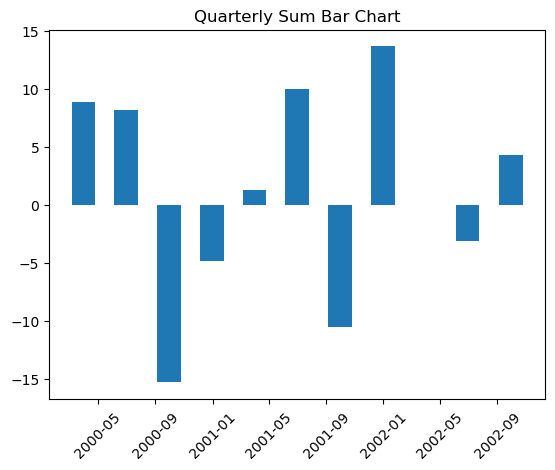

In [15]:
# Jo quarterly sum humne upar nikala, yeh usko ek khubsoorat Bar Chart (dandey wala graph) mein convert kar dega.
# Quarterly sum ka Bar Chart banana
plt.bar(
    x=longer_ts.resample("Q").sum().index,
    height=longer_ts.resample("Q").sum().values,
    width=50,
)  # width se bars sahi size ki lagengi
plt.title("Quarterly Sum Bar Chart")
plt.xticks(rotation=45)
plt.show()

In [16]:
# Sabse pehle saari zaroori libraries ek sath import kar lete hain.
from datetime import datetime
import matplotlib.pyplot as plt
import pandas as pd
import requests

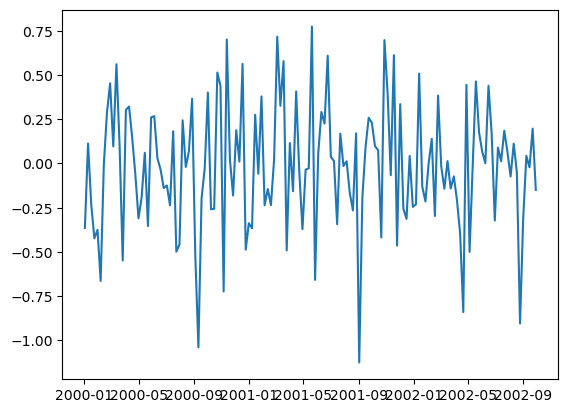

In [59]:
import matplotlib.pyplot as plt
plt.plot(longer_ts.resample('W').mean())

In [17]:
# Yahan hum live price aur timestamp nikal rahe hain.
url = "https://api.coingecko.com/api/v3/simple/price"

params = {
    "ids": "bitcoin",
    "vs_currencies": "usd",
    "include_last_updated_at": "true",
}

response = requests.get(url, params=params)
data = response.json()

# Live Timestamp aur Price nikalna
timestamp = datetime.fromtimestamp(data["bitcoin"]["last_updated_at"])
price = data["bitcoin"]["usd"]

print("Timestamp:", timestamp)
print("Price in USD:", price)

Timestamp: 2026-07-09 11:52:53
Price in USD: 62799


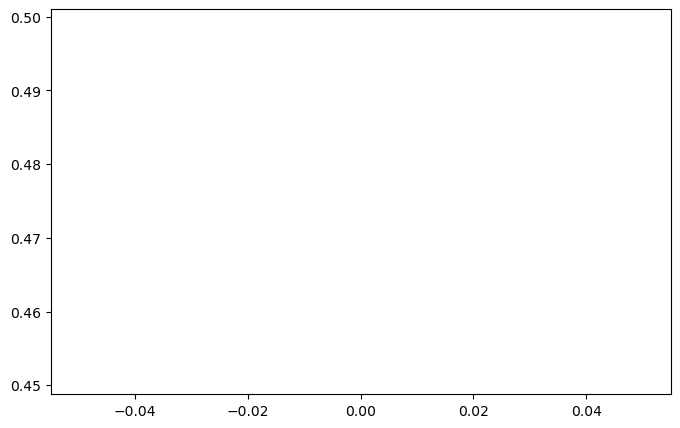

In [61]:
plt.plot(longer_ts['2000-01-01'].cumsum())

In [57]:
longer_ts = pd.Series(np.random.randn(1000),index=pd.date_range('1/1/2000', periods=1000, freq='D'))
longer_ts

2000-01-01    0.474890
2000-01-02   -1.203900
2000-01-03   -0.248766
2000-01-04    1.794537
2000-01-05    2.017617
                ...   
2002-09-22   -1.825096
2002-09-23    0.083300
2002-09-24   -1.338392
2002-09-25    0.743482
2002-09-26   -0.086517
Freq: D, Length: 1000, dtype: float64

In [27]:
 longer_ts.resample('Q').sum()

C:\Users\Adil\AppData\Local\Temp\ipykernel_15308\455268303.py:1: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  longer_ts.resample('Q').sum()


2000-03-31     3.980136
2000-06-30    -5.773146
2000-09-30     3.784772
2000-12-31    -2.607163
2001-03-31    18.734848
2001-06-30    -3.518673
2001-09-30    -2.901200
2001-12-31    -8.793621
2002-03-31     9.070923
2002-06-30    -4.084823
2002-09-30   -11.635179
Freq: QE-DEC, dtype: float64

C:\Users\Adil\AppData\Local\Temp\ipykernel_15308\2335723572.py:1: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  plt.bar(x=longer_ts.resample('Q').sum().index, height=longer_ts.resample('Q').sum().values)


<BarContainer object of 11 artists>

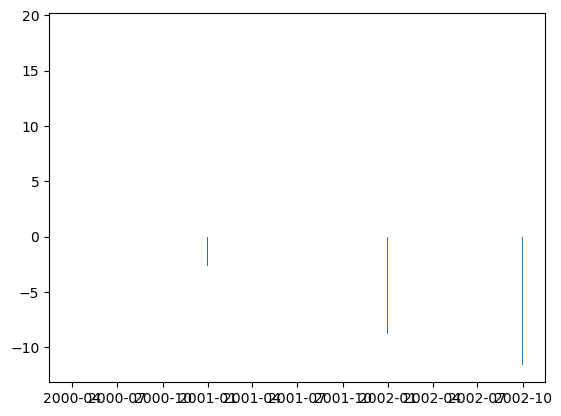

In [28]:
plt.bar(x=longer_ts.resample('Q').sum().index, height=longer_ts.resample('Q').sum().values)

In [30]:
import requests

In [32]:
import requests
from datetime import datetime

url = "https://api.coingecko.com/api/v3/simple/price"

params = {
    "ids": "bitcoin",
    "vs_currencies": "usd",
    "include_last_updated_at": "true"
}

response = requests.get(url, params=params)
data = response.json()

timestamp = datetime.fromtimestamp(data["bitcoin"]["last_updated_at"])

print("Timestamp:", timestamp)
print("Price:", data["bitcoin"]["usd"])

Timestamp: 2026-07-09 15:29:38
Price: 62831


In [33]:
timestamp

datetime.datetime(2026, 7, 9, 15, 29, 38)

In [42]:
data


{'bitcoin': {'usd': 62831, 'last_updated_at': 1783592978}}

In [49]:
!pip install yfinance

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 2.6 MB/s eta 0:00:01
   ------------------------------- -------- 1.3/1.7 MB 3.0 MB/s eta 0:00:01
   ------------------------------------- -- 1.6/1.7 MB 2.9 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 1.2 MB/s  0:00:01

   ---------------------------------------- 0/5 [peewee]
   ---------------------------------------- 0/5 [peewee]
   ---------------------------------------- 0/5 [peewee]
   -------- ------------------------------- 1/5 [multitasking]
   ---------------- ----------------------- 2/5 [websockets]
   ---------------- ----------------------- 2/5 [websockets]
   ---------------- ----------------------- 2/5 [websockets]
   ---------------- ----------------------- 2/5 [websockets]
   ---------------- ----------------------- 2/5 [websockets]
   ------------------------ --------------- 3/5 [curl_cffi]
   ------------------------ --

In [50]:
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

In [51]:
# Stock ticker aur dates set kar ke data download karna
df = yf.download("AAPL", start="2025-01-01", end="2026-07-07")

[*********************100%***********************]  1 of 1 completed


In [52]:
# DataFrame ko dekhna
df.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2025-01-02,242.301926,247.518596,240.284814,247.349662,55740700
2025-01-03,241.815033,242.629819,240.354364,241.815033,40244100
2025-01-06,243.444611,245.759820,241.656035,242.758989,45045600
2025-01-07,240.672333,243.991125,239.817792,241.437433,40856000
2025-01-08,241.159210,242.162808,238.526040,240.384163,37628900


In [58]:
# Check karna ke dates index par hain ya nahi
ts.index

DatetimeIndex(['2025-01-02', '2025-01-03', '2025-01-06', '2025-01-07',
               '2025-01-08', '2025-01-10', '2025-01-13', '2025-01-14',
               '2025-01-15', '2025-01-16',
               ...
               '2026-06-22', '2026-06-23', '2026-06-24', '2026-06-25',
               '2026-06-26', '2026-06-29', '2026-06-30', '2026-07-01',
               '2026-07-02', '2026-07-06'],
              dtype='datetime64[ns]', name='Date', length=376, freq=None)

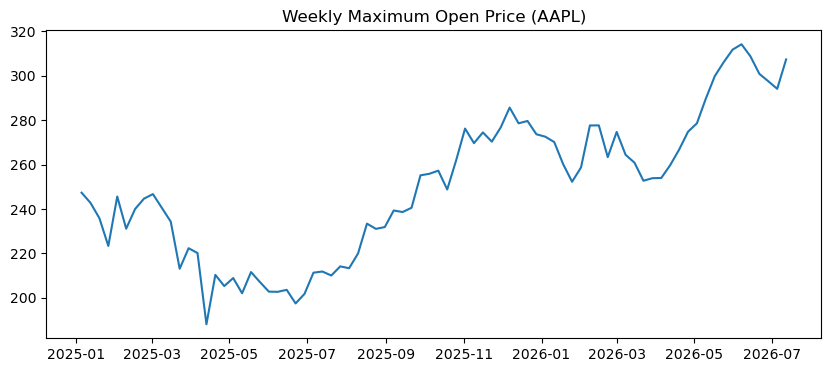

In [56]:
# Haftawar (Weekly) max price ka graph banana
plt.figure(figsize=(10, 4))
plt.plot(ts.resample("W").max())
plt.title("Weekly Maximum Open Price (AAPL)")
plt.show()